In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn nltk streamlit joblib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 119.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 109.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [2]:
import urllib.request

fake_url = "https://raw.githubusercontent.com/Reinforz/Fake-News-detection-with-ISOT-Dataset/main/Fake.csv"
true_url = "https://raw.githubusercontent.com/Reinforz/Fake-News-detection-with-ISOT-Dataset/main/True.csv"

urllib.request.urlretrieve(fake_url, "Fake.csv")
urllib.request.urlretrieve(true_url, "True.csv")

print("Both datasets downloaded successfully!")

Both datasets downloaded successfully!


In [3]:
import pandas as pd

# Load fake and real news datasets
fake_df = pd.read_csv("Fake.csv")
true_df = pd.read_csv("True.csv")

# Add labels
fake_df["label"] = 0
true_df["label"] = 1

# Combine both datasets
df = pd.concat([fake_df, true_df], ignore_index=True)

# Display first 5 rows
df.head()

,title,text,subject,date,label
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",0
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",0
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",0
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017",0
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017",0


In [4]:
# Check dataset size
print("Dataset Shape:", df.shape)

# Check column names
print("\nColumns:")
print(df.columns)

# Check fake and real news counts
print("\nNews Distribution:")
print(df["label"].value_counts())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (44898, 5)

Columns:
Index(['title', 'text', 'subject', 'date', 'label'], dtype='object')

News Distribution:
label
0    23481
1    21417
Name: count, dtype: int64

Missing Values:
title      0
text       0
subject    0
date       0
label      0
dtype: int64


In [5]:
import re
import nltk

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)
    words = text.split()
    words = [lemmatizer.lemmatize(word)
             for word in words if word not in stop_words]
    return ' '.join(words)

df['clean_text'] = df['title'] + ' ' + df['text']
df['clean_text'] = df['clean_text'].apply(clean_text)

df[['text', 'clean_text']].head()

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


,text,clean_text
0,Donald Trump just couldn t wish all Americans ...,donald trump sends embarrassing new year eve m...
1,House Intelligence Committee Chairman Devin Nu...,drunk bragging trump staffer started russian c...
2,"On Friday, it was revealed that former Milwauk...",sheriff david clarke becomes internet joke thr...
3,"On Christmas day, Donald Trump announced that ...",trump obsessed even obamas name coded website ...
4,Pope Francis used his annual Christmas Day mes...,pope francis called donald trump christmas spe...


In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Convert text into numerical features
tfidf = TfidfVectorizer(max_features=5000)

X = tfidf.fit_transform(df['clean_text'])

# Target labels
y = df['label']

print("TF-IDF Shape:", X.shape)
print("Target Shape:", y.shape)

TF-IDF Shape: (44898, 5000)
Target Shape: (44898,)


In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (35918, 5000)
Testing data: (8980, 5000)


In [8]:
from sklearn.linear_model import LogisticRegression

# Create the model
lr_model = LogisticRegression(max_iter=1000)

# Train the model
lr_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [9]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Make predictions
y_pred_lr = lr_model.predict(X_test)

# Calculate accuracy
accuracy_lr = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Accuracy:", accuracy_lr * 100, "%")

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

Logistic Regression Accuracy: 98.69710467706014 %

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.98      0.99      4696
           1       0.98      0.99      0.99      4284

    accuracy                           0.99      8980
   macro avg       0.99      0.99      0.99      8980
weighted avg       0.99      0.99      0.99      8980


Confusion Matrix:
[[4622   74]
 [  43 4241]]


In [10]:
from sklearn.naive_bayes import MultinomialNB

# Create the model
nb_model = MultinomialNB()

# Train the model
nb_model.fit(X_train, y_train)

print("Multinomial Naive Bayes model trained successfully!")

Multinomial Naive Bayes model trained successfully!


In [11]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Make predictions
y_pred_nb = nb_model.predict(X_test)

# Calculate accuracy
accuracy_nb = accuracy_score(y_test, y_pred_nb)

print("Naive Bayes Accuracy:", accuracy_nb * 100, "%")

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_nb))

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_nb))

Naive Bayes Accuracy: 93.46325167037863 %

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.94      0.94      4696
           1       0.93      0.93      0.93      4284

    accuracy                           0.93      8980
   macro avg       0.93      0.93      0.93      8980
weighted avg       0.93      0.93      0.93      8980


Confusion Matrix:
[[4408  288]
 [ 299 3985]]


In [12]:
comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Multinomial Naive Bayes'],
    'Accuracy': [accuracy_lr, accuracy_nb]
})

comparison['Accuracy'] = comparison['Accuracy'] * 100

print(comparison)

                     Model   Accuracy
0      Logistic Regression  98.697105
1  Multinomial Naive Bayes  93.463252


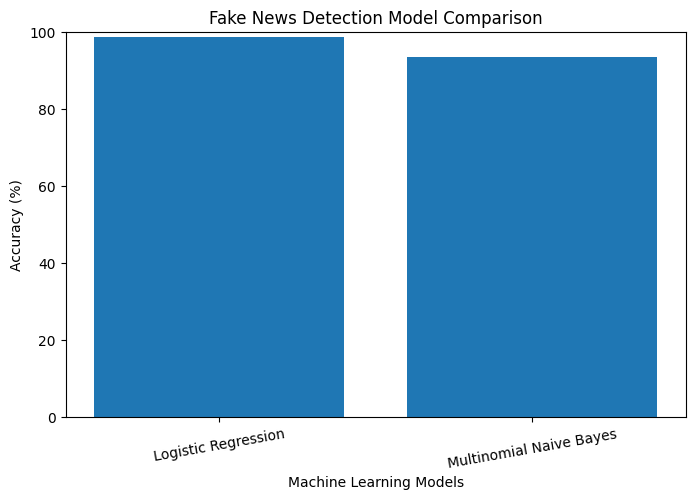

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Multinomial Naive Bayes'],
    'Accuracy': [accuracy_lr * 100, accuracy_nb * 100]
})

plt.figure(figsize=(8, 5))
plt.bar(comparison['Model'], comparison['Accuracy'])

plt.title('Fake News Detection Model Comparison')
plt.xlabel('Machine Learning Models')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 100)
plt.xticks(rotation=10)

plt.show()

In [16]:
import joblib

# Save Logistic Regression model
joblib.dump(lr_model, 'logistic_regression_model.pkl')

# Save Naive Bayes model
joblib.dump(nb_model, 'naive_bayes_model.pkl')

# Save TF-IDF vectorizer
joblib.dump(tfidf, 'tfidf_vectorizer.pkl')

print("All models and vectorizer saved successfully!")

All models and vectorizer saved successfully!


In [17]:
def predict_news(news):
    cleaned = clean_text(news)
    vectorized = tfidf.transform([cleaned])

    prediction = lr_model.predict(vectorized)[0]
    probability = lr_model.predict_proba(vectorized)[0]

    if prediction == 0:
        print("Prediction: FAKE NEWS")
    else:
        print("Prediction: REAL NEWS")

    print("Confidence:", round(max(probability) * 100, 2), "%")


# Test example
predict_news("Scientists discover a new planet in space")

Prediction: FAKE NEWS
Confidence: 78.84 %


In [18]:
%%writefile app.py

import streamlit as st
import joblib
import re
import nltk

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

model = joblib.load('logistic_regression_model.pkl')
tfidf = joblib.load('tfidf_vectorizer.pkl')

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)
    words = text.split()
    words = [lemmatizer.lemmatize(word)
             for word in words if word not in stop_words]
    return ' '.join(words)

st.title("Smart Fake News Detection System")
st.write("Enter a news article to check its predicted category.")

news = st.text_area("Enter News Article")

if st.button("Detect News"):
    if news.strip():
        cleaned = clean_text(news)
        vectorized = tfidf.transform([cleaned])

        prediction = model.predict(vectorized)[0]
        probability = model.predict_proba(vectorized)[0]

        if prediction == 0:
            st.error("Prediction: FAKE NEWS")
        else:
            st.success("Prediction: REAL NEWS")

        st.write("Model confidence:",
                 round(max(probability) * 100, 2), "%")
    else:
        st.warning("Please enter a news article.")

Writing app.py


In [19]:
!pip install streamlit pyngrok

In [20]:
from pyngrok import ngrok
from getpass import getpass

ngrok_token = getpass("Enter your ngrok Authtoken: ")

ngrok.set_auth_token(ngrok_token)

print("ngrok authentication configured successfully!")

Enter your ngrok Authtoken: ··········
ngrok authentication configured successfully!


In [21]:
import subprocess
import time

# Start Streamlit in the background
process = subprocess.Popen(
    ["streamlit", "run", "app.py", "--server.port", "8501"],
    stdout=subprocess.PIPE,
    stderr=subprocess.PIPE
)

time.sleep(5)

# Create public URL
public_url = ngrok.connect(8501)

print("Your Streamlit App is running!")
print(public_url)

Your Streamlit App is running!
NgrokTunnel: "https://passivism-flashing-winter.ngrok-free.dev" -> "http://localhost:8501"
